# 01 — Explore sub-001 (Makin et al. 2012, OpenNeuro ds004347)

**Purpose.** First exploration of the dataset for the Jacobsen-2006-style
implicit-learning EEG experiment (Makin et al. 2012, OpenNeuro
**ds004347**, local BIDS root `data/on004347`).  One subject (sub-001) is
inspected end to end: recording metadata, event structure, a raw-data
plot with events marked (M2 deliverable), a PSD to document line noise
and drift, and a first statistical look at candidate bad channels.

**Dataset / download.** The dataset is fetched from OpenNeuro by
`src.download.download_dataset()` (mne-bids / OpenNeuro):

```python
from src.download import download_dataset
download_dataset()   # -> data/on004347, sub-001 only
```

It is *not* run here — the notebook assumes the data are already on disk.

In [1]:
import sys
from pathlib import Path

# Make `src` importable from notebooks/.
sys.path.append(str(Path.cwd().resolve().parent))

## Load sub-001 and recording metadata

`src.io.load_raw` wraps `read_raw_bids` and fixes the known dataset
issues (quoted channel names in `channels.tsv`, EXG1-8 typed `eog`,
BDF `Status` trigger channel dropped, `biosemi64` montage).

In [2]:
import src.io

raw = src.io.load_raw('001', preload=True)
raw.info

sfreq = raw.info['sfreq']
duration = raw.n_times / sfreq
print(f'sfreq          : {sfreq} Hz')
print(f'duration       : {duration:.1f} s = {duration / 60:.1f} min')

from collections import Counter
type_counts = Counter(t for t in raw.get_channel_types() if t != 'stab')
print('channel types  :', dict(sorted(type_counts.items())))

import json
eeg_json = json.loads(Path(f"{src.io.BIDS_ROOT}/sub-001/eeg/sub-001_task-{src.io.TASK}_eeg.json").read_text(encoding='utf-8'))
print('EEGReference        :', eeg_json['EEGReference'])
print('PowerLineFrequency  :', eeg_json['PowerLineFrequency'], 'Hz')
print('HardwareFilters     :', eeg_json.get('HardwareFilters'))
print('-> reference is CMS/DRL (active electrodes, BioSemi), NOT a mastoid/ear reference;')
print('   an average or linked-mastoid re-reference is needed before ERP comparison -> M3.')
print('-> PowerLineFrequency is 50 Hz (UK mains), and there is no hardware high-pass.')

Extracting BDF parameters from C:\Users\DIOS\Desktop\eeg\repo\EEG\data\on004347\sub-001\eeg\sub-001_task-jacobsen_eeg.bdf...


Setting channel info structure...


Creating raw.info structure...


"trial_type" all "n/a"; using "value" instead.


Reading channel info from C:\Users\DIOS\Desktop\eeg\repo\EEG\data\on004347\sub-001\eeg\sub-001_task-jacobsen_channels.tsv.


Reading electrode coords from C:\Users\DIOS\Desktop\eeg\repo\EEG\data\on004347\sub-001\eeg\sub-001_task-jacobsen_electrodes.tsv.


Reading 0 ... 531967  =      0.000 ...  1038.998 secs...


C:\Users\DIOS\Desktop\eeg\repo\EEG\src\io.py:174: RuntimeWarning: No fiducial points found for ctf_head montage. Synthesizing approximate fiducials (nasion, LPA, RPA) from electrode geometry with estimated head radius 0.0813.
  raw = read_raw_bids(bids_path, on_ch_mismatch="warn")
C:\Users\DIOS\Desktop\eeg\repo\EEG\src\io.py:174: RuntimeWarning: There are channels without locations (n/a) that are not marked as bad: ["'EXG1'", "'EXG2'", "'EXG3'", "'EXG4'", "'EXG5'", "'EXG6'", "'EXG7'", "'EXG8'"]
  raw = read_raw_bids(bids_path, on_ch_mismatch="warn")
C:\Users\DIOS\Desktop\eeg\repo\EEG\src\io.py:174: RuntimeWarning: DigMontage is only a subset of info. There are 72 channel positions not present in the DigMontage. The channels missing from the montage are:

['Fp1', 'AF7', 'AF3', 'F1', 'F3', 'F5', 'F7', 'FT7', 'FC5', 'FC3', 'FC1', 'C1', 'C3', 'C5', 'T7', 'TP7', 'CP5', 'CP3', 'CP1', 'P1', 'P3', 'P5', 'P7', 'P9', 'PO7', 'PO3', 'O1', 'Iz', 'Oz', 'POz', 'Pz', 'CPz', 'Fpz', 'Fp2', 'AF8', 'AF4',

sfreq          : 512.0 Hz
duration       : 1039.0 s = 17.3 min
channel types  : {'eeg': 64, 'eog': 8}
EEGReference        : CMS/DRL
PowerLineFrequency  : 50 Hz
HardwareFilters     : n/a
-> reference is CMS/DRL (active electrodes, BioSemi), NOT a mastoid/ear reference;
   an average or linked-mastoid re-reference is needed before ERP comparison -> M3.
-> PowerLineFrequency is 50 Hz (UK mains), and there is no hardware high-pass.


## Events per condition and inter-trial intervals

Stimulus codes: `1` = reflection, `3` = random (from `events.json`);
`255` marks block starts and is ignored.  Onsets are read as **seconds**
even though `events.json` claims the unit is `ms` — another dataset
inconsistency documented in `src/io.py`.

In [3]:
import numpy as np
events, event_id = src.io.get_events(raw)
print('event_id       :', event_id)

counts = {name: int((events[:, 2] == code).sum()) for name, code in event_id.items()}
print('event counts   :', counts)
print('total          :', len(events))

# Inter-trial interval (onset-to-onset across both conditions).
onsets = events[:, 0] / sfreq
isi = np.diff(onsets)
print(f'ITI (onset-to-onset): mean {isi.mean():.3f} s, std {isi.std():.3f} s, '
      f'min {isi.min():.3f} s, max {isi.max():.3f} s')
print(f'ITI quantiles (25/50/75%): {np.percentile(isi, [25, 50, 75]).round(3)}')

event_id       : {'reflection': 1, 'random': 3}
event counts   : {'reflection': 80, 'random': 79}
total          : 159
ITI (onset-to-onset): mean 6.387 s, std 2.301 s, min 5.170 s, max 32.301 s
ITI quantiles (25/50/75%): [5.631 6.007 6.43 ]


## Raw data with events, and PSD

Figures are saved to `docs/figures/` (the M2 deliverables):
`sub-001_raw_events.png` (~20 s of raw EEG, events marked, 50 µV scalings)
and `sub-001_psd.png`.

Using matplotlib as 2D backend.


For automatic theme detection, "darkdetect" has to be installed! You can install it with `pip install darkdetect`


Effective window size : 4.000 (s)


Plotting power spectral density (dB=True).


saved: C:\Users\DIOS\Desktop\eeg\repo\EEG\docs\figures\sub-001_raw_events.png
saved: C:\Users\DIOS\Desktop\eeg\repo\EEG\docs\figures\sub-001_psd.png


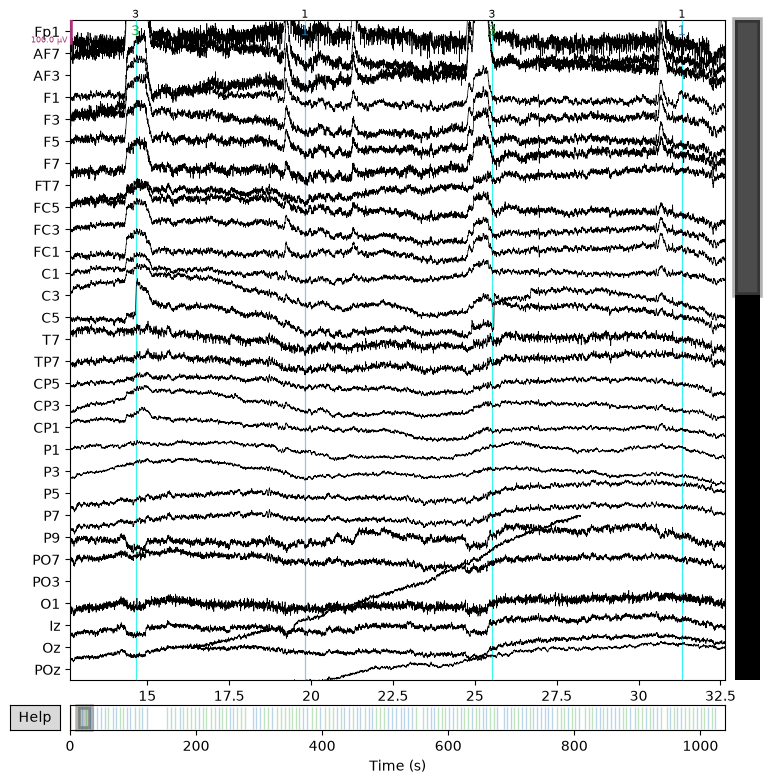

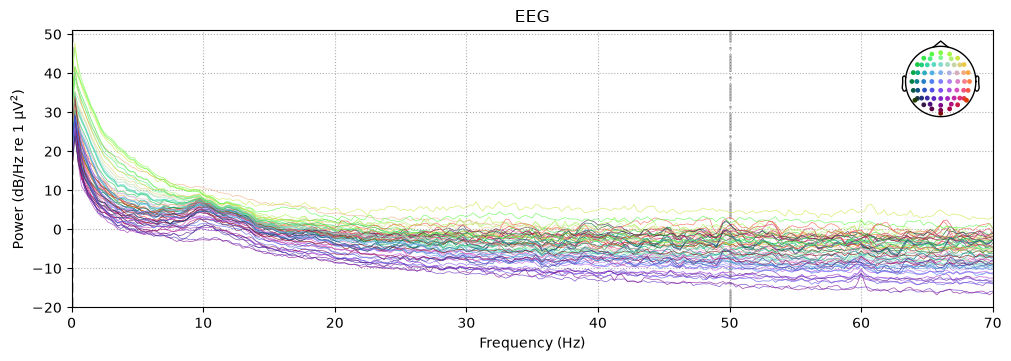

In [4]:
import src.plotting
from pathlib import Path

FIG = Path('..') / 'docs' / 'figures'
FIG.mkdir(parents=True, exist_ok=True)

fig = src.plotting.plot_raw_with_events(
    raw, events, event_id,
    fname=FIG / 'sub-001_raw_events.png',
)
psd_fig = src.plotting.plot_psd(raw, fmax=70, fname=FIG / 'sub-001_psd.png')
print('saved:', (FIG / 'sub-001_raw_events.png').resolve())
print('saved:', (FIG / 'sub-001_psd.png').resolve())

## Per-channel variability and candidate bad channels

**Why the 1–40 Hz copy?** The BioSemi recording has no hardware high-pass, so
its per-channel std on the raw data is dominated by the DC offset and slow
drift of each electrode (median raw std was ~508 µV — pure drift, data quality
invisible in it). A channel therefore ranked as "bad" on raw std was really
just the channel that drifted the most, not the noisiest one.

So this check runs on a **copy** of the EEG, band-passed to **1–40 Hz**
(`raw.copy().pick('eeg').filter(1, 40)`) — the copy exists only for this
diagnostic; the original raw data is untouched (filtering choices are made in
M3). We compute the per-channel std in µV and a **two-sided robust z-score**
against the median across channels:

z = (std − median) / (1.4826 · MAD), flagged when |z| > 3

(two-sided, because *low* std — a flat, high-impedance contact — is just as
suspicious as high std).

In [5]:
raw_1_40 = raw.copy().pick('eeg').filter(1, 40, verbose=False)
X = raw_1_40.get_data() * 1e6  # µV
stds = X.std(axis=1)
names = raw_1_40.ch_names

med = np.median(stds)
mad = np.median(np.abs(stds - med))
z = (stds - med) / (1.4826 * mad)
flag_idx = np.where(np.abs(z) > 3)[0]

print(f'1-40 Hz copy, per-channel std: median {med:.2f} µV, MAD {mad:.2f} µV')
for name in ('PO7', 'PO8', 'PO3'):
    i = names.index(name)
    print(f'  {name}: std {stds[i]:.2f} µV, robust z {z[i]:+.2f}')

flagged = [(names[i], round(float(stds[i]), 2), round(float(z[i]), 2)) for i in flag_idx]
print(f'flagged channels (|z| > 3): {len(flagged)}')
for name, s, zz in flagged:
    print(f'  {name}: std {s:.2f} µV, z {zz:+.2f}')

1-40 Hz copy, per-channel std: median 12.08 µV, MAD 4.20 µV
  PO7: std 10.15 µV, robust z -0.31
  PO8: std 16.33 µV, robust z +0.68
  PO3: std 5.54 µV, robust z -1.05
flagged channels (|z| > 3): 10
  Fp1: std 68.34 µV, z +9.04
  AF7: std 47.27 µV, z +5.65
  AF3: std 40.83 µV, z +4.62
  Fpz: std 73.94 µV, z +9.94
  Fp2: std 64.73 µV, z +8.46
  AF8: std 59.39 µV, z +7.60
  AF4: std 43.63 µV, z +5.07
  AFz: std 35.96 µV, z +3.84
  F8: std 35.74 µV, z +3.80
  FC6: std 38.86 µV, z +4.30


## Observations & open doubts

### Observations (from the actual outputs above and the saved figures)

- **Recording**: 512 Hz, ~1039 s (~17.3 min); 64 EEG + 8 EOG (EXG1-8) channels.
- **Reference**: `EEGReference: CMS/DRL` (BioSemi active electrodes) — not a
  mastoid reference, so an average (or linked-mastoid) re-reference is needed
  before ERP comparison (-> M3). `PowerLineFrequency: 50` Hz, no hardware filters.
- **Events**: 160 stimulus trials expected from the design, but only **159 found**
  (80 reflection, 79 random) — exactly one random trial is missing from
  `events.tsv`. To be confirmed against the BDF `Status` channel in M3.
- **Inter-trial interval**: onset-to-onset mean 6.39 s, SD 2.30 s, min 5.17 s,
  max 32.30 s (median 6.01 s). The 32 s max is the pause between blocks or a
  skipped trial — worth re-checking when the missing random trial is investigated.
- **Blinks/ocular artifacts**: large frontal deflections on **Fp1/AF7** (and less
  on Fp2/AF8) in the raw plot — classic blink/VEOG pattern. ICA in M3.
- **Slow drift**: strong low-frequency drift throughout (no hardware high-pass),
  visible as the slow wander of most traces. On the **raw** std this drift
  dominates completely (median ~508 µV), which is why the bad-channel scan now
  runs on the 1–40 Hz copy instead.
- **Candidate bad channels** (1–40 Hz copy, robust z on std, |z| > 3): median
  std **12.08 µV**, MAD 4.20 µV. The **10 flagged channels are all frontal or
  fronto-lateral** — Fp1, Fp2, Fpz, AF3, AFz, AF4, AF7, AF8, F8, FC6. Their huge
  stds (36–74 µV) are **blinks**, not bad electrodes (see the Fp1/AF7 look in the
  raw plot), so this is exactly the artifact ICA will remove in M3 — they are
  **not** manually marked as bad channels.
- **PO7 is fine**: std 10.15 µV, robust z −0.31 — comfortably inside the
  distribution, and one of our two analysis channels. The earlier impression
  that PO7 was bad came entirely from its raw-data drift once the DC/drift
  dominance was removed.
- **PO8**: std 16.33 µV, z +0.68 — slightly noisy but well within the spread.
- **PO3 looks flat** in the raw plot, and the filterless check confirms it is
  *quiet*, not bad: std 5.54 µV, z −1.05 (a low-impedance-looking contact that
  picks up little). It is not sucked out by the noise flag; it stays on the
  visual-suspicion list for M3.
- **PSD**: clear alpha peak at **~10 Hz**; only a **tiny 50 Hz** line peak, so a
  notch filter is probably unnecessary (decided from the data, not by default)
  and a **small but visible 60 Hz peak** in some channels, which makes the notch
  question genuinely open.

### Open doubts about the dataset

1. **Quoted channel names** in `channels.tsv` (`'Fp1'` with literal quotes) —
   worked around in `src/io.py` (types and montage re-applied by hand).
2. **EXG1-8 all labelled EOG** in `channels.tsv`, but the paper recorded facial
   **EMG** (zygomaticus, corrugator) as well; no per-channel mapping is given.
   Which EXG channel is HEOG/VEOG/EMG is unknown (TODO in `src/io.py`).
3. `events.json` says onsets are in **"ms"**, but the actual onsets in
   `events.tsv` are in **seconds** — mne-bids reads them as seconds (correct).
4. The **60 Hz peak in a few channels** is unexpected for a UK lab (mains is
   50 Hz) — possibly an American-made piece of equipment or an aliasing
   artifact; open question to raise on the course forum (OpenNeuro ds004347).
